# Decision Tree on TF-IDF

This notebook trains a single decision tree on the same TF-IDF features and train/test split as the Logistic Regression baseline. A shallow tree can be read in full, so it is a useful contrast to the Random Forest, and the post-hoc methods below show how far they agree with what the tree visibly does.

The explanation steps follow the course's interpretation pipeline: global importance (PFI / SHAP) → feature effects (PDP) → heterogeneity (ICE) → individual decisions (LIME / SHAP).

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from IPython.display import display
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score
)
from sklearn.inspection import PartialDependenceDisplay

from lime.lime_text import LimeTextExplainer
from lime.submodular_pick import SubmodularPick
import shap

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, RANDOM_STATE
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,Foreign Democrat final.,more tax development both store agreement lawy...,real,0
1,To offer down resource great point.,probably guess western behind likely next inve...,fake,1
2,Himself church myself carry.,them identify forward present success risk sev...,fake,1
3,You unit its should.,phone which item yard Republican safe where po...,fake,1
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,fake,1


## 3. Text Preprocessing

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,Foreign Democrat final. more tax development b...,foreign democrat final tax development store a...
1,To offer down resource great point. probably g...,offer resource great point probably guess west...
2,Himself church myself carry. them identify for...,church carry identify forward present success ...
3,You unit its should. phone which item yard Rep...,unit phone item yard republican safe police id...
4,Billion believe employee summer how. wonder my...,billion believe employee summer wonder fact di...


Quick check: compare one raw vs. processed example side by side.

In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 Foreign Democrat final. more tax development both store agreement lawyer hear outside continue reach difference yeah figure your power fear identify there protect security great national nothing fast story why late nearly bit cost tough since question to power almost future young conference behind a

PROCESSED:
 foreign democrat final tax development store agreement lawyer hear outside continue reach difference yeah figure power fear identify protect security great national nothing fast story late nearly bit cost tough since question power almost future young conference behind ahead building teach million b


## 4. TF-IDF Vectorization

In [5]:
X, y, tfidf = get_tfidf_features(df)
feature_names = tfidf.get_feature_names_out()

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (20000, 867)


## 5. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test = get_train_test_split(X, y)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (16000, 867)
Test shape: (4000, 867)

Train class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64

Test class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64


## 6. Train Decision Tree

We use a single decision tree limited to a depth of 3, with at least 50 training articles in every leaf, so that no rule rests on a handful of chance cases. A tree of this size has at most 7 decision points and 8 leaves, in line with the 7 ± 2 limit on human working memory, so a reader can follow any prediction from the top question to its answer and can hold the whole tree in mind at once. This matters when the model is audited, because the model should stay simulatable: an auditor can take an article, answer each question in turn, reach the same prediction the model made, and check every rule for anything unreasonable. A deeper tree quickly makes this impossible, since the size of a tree roughly doubles with each extra level. A depth of 5 allows up to 31 decision points, a depth of 7 up to 127, and a depth of 10 up to 1,023, which is far more than a person can read, remember or check, even though each single prediction would still follow a path of only 5, 7 or 10 questions. The cost of choosing a depth of 3 is flexibility: the tree can only ask a few questions, so it can use only a handful of the 867 terms.

In [7]:
dt = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)

### 6.1 The Tree Itself

Unlike the Random Forest, the whole model fits on one page. The text version and the diagram below show every question the tree asks and what it predicts at the end. In each box, the first line is the question asked of an article (the TF-IDF weight of a term compared with a cutoff), and the box also shows the share of training articles that reached it and the class predicted there.

In [8]:
used_idx = np.unique(dt.tree_.feature[dt.tree_.feature >= 0])
print("Terms used by the tree:", list(feature_names[used_idx]))
print()
print(export_text(dt, feature_names=list(feature_names)))

Terms used by the tree: ['environmental', 'good', 'purpose', 'save', 'significant', 'wrong']

|--- good <= 0.07
|   |--- significant <= 0.06
|   |   |--- wrong <= 0.06
|   |   |   |--- class: 0
|   |   |--- wrong >  0.06
|   |   |   |--- class: 1
|   |--- significant >  0.06
|   |   |--- environmental <= 0.06
|   |   |   |--- class: 1
|   |   |--- environmental >  0.06
|   |   |   |--- class: 0
|--- good >  0.07
|   |--- save <= 0.06
|   |   |--- purpose <= 0.07
|   |   |   |--- class: 1
|   |   |--- purpose >  0.07
|   |   |   |--- class: 1
|   |--- save >  0.06
|   |   |--- class: 0



The tree uses six terms (environmental, good, purpose, save, significant and wrong) and asks at most three questions about any article. Each question compares the TF-IDF weight of one term in the article with a small cutoff of 0.06 or 0.07. The first question is about good. If the article has little or none of it, the tree asks about significant: with little significant it predicts fake only when wrong is present, and with more significant it predicts fake unless environmental is also present. If the article has more good, the tree asks about save: with little save it predicts fake, and with more save it predicts real. The question about purpose does not change any prediction, because both of its leaves predict fake, so it only changes how confident the tree is. The tree has 6 decision points and 7 leaves, one fewer of each than the maximum for a depth of 3, because the branch ending in save stops after a single question.

The terms are ordinary words, and none is an obvious marker of fabricated reporting. Good, significant and wrong are also words that pointed toward fake in the baseline, so the tree finds part of what the logistic regression found. The whole model can be checked by hand in a few seconds, which is its main strength, but whether these rules reflect a real difference between fake and real articles depends on the performance results below.

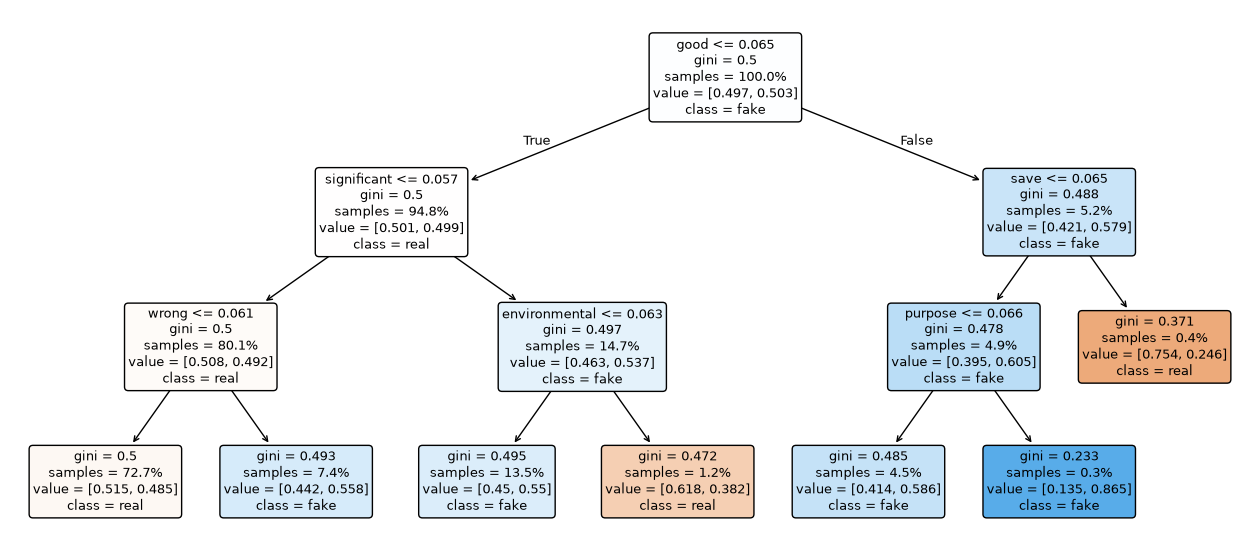

In [9]:
plt.figure(figsize=(16, 7))
plot_tree(dt, feature_names=list(feature_names), class_names=["real", "fake"],
          filled=True, rounded=True, proportion=True, fontsize=9)
plt.show()

Each box in the diagram shows the question asked of an article, the share of training articles that reach it (samples), the share of real and fake articles among them (value, in the order real then fake), and the class the tree predicts there. Gini measures how mixed a box is, from 0 for a box with only one class to 0.5 for an even split. Blue boxes lean toward fake and orange boxes toward real, and a darker color means a stronger lean. The root is an even split of 49.7% real and 50.3% fake, and almost every article (94.8%) goes left because it has little or none of the word good.

The diagram shows how little the tree separates the two classes. Five of the seven leaves have a gini between 0.47 and 0.5, which means they are almost evenly mixed, and the largest leaf, which holds 72.7% of all articles, contains 51.5% real and 48.5% fake, so predicting real for those articles is only slightly better than a coin flip. The only clear leanings are in two very small leaves: the leaf for articles with more purpose holds 0.3% of articles and is 86.5% fake, and the leaf for articles with more save holds 0.4% and is 75.4% real. Together they cover less than 1% of articles, and because they rest on so few articles and the tree searched hundreds of terms for its best splits, they may partly be chance. Overall, the tree labels about three quarters of the training articles real (the three orange leaves hold 74.3%) and only about a quarter fake, so it will miss many fake articles, which the next section checks.

### 6.2 Why Not a Deeper Tree?

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for depth in [3, 5, 7, 10]:
    cv_model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=50, random_state=RANDOM_STATE)
    cv_pred = cross_val_predict(cv_model, X_train, y_train, cv=skf)
    rows.append({
        "max_depth": depth,
        "max_splits": 2**depth - 1,
        "max_leaves": 2**depth,
        "cv_accuracy": round(accuracy_score(y_train, cv_pred), 3),
        "cv_fake_recall": round(recall_score(y_train, cv_pred, pos_label=1), 3),
        "share_predicted_fake": round(cv_pred.mean(), 3),
    })
pd.DataFrame(rows)

,max_depth,max_splits,max_leaves,cv_accuracy,cv_fake_recall,share_predicted_fake
0,3,7,8,0.503,0.501,0.498
1,5,31,32,0.507,0.259,0.251
2,7,127,128,0.503,0.338,0.334
3,10,1023,1024,0.499,0.402,0.402


Cross-validated accuracy on the training set stays between 0.499 and 0.507 at every depth, so the larger trees are no better at telling fake from real, and the extra splits would make the tree harder to audit without making it more accurate. Fake-class recall changes with depth (0.501 at depth 3, 0.259 at depth 5, 0.338 at depth 7 and 0.402 at depth 10) only because the share of articles each tree labels as fake changes by almost the same amount, so it does not show better detection.

## 7. Validate Predictive Performance

In [11]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
train_recall = recall_score(y_train, dt.predict(X_train), pos_label=1)

print(f"Fake-class recall (test):  {recall_fake:.4f}")
print(f"Fake-class recall (train): {train_recall:.4f}")
print(f"Accuracy (test): {accuracy:.4f}")
print(f"Share of test articles predicted fake: {y_pred.mean():.3f}")

              precision    recall  f1-score   support

        real       0.51      0.75      0.61      1989
        fake       0.53      0.28      0.37      2011

    accuracy                           0.51      4000
   macro avg       0.52      0.52      0.49      4000
weighted avg       0.52      0.51      0.49      4000

Fake-class recall (test):  0.2805
Fake-class recall (train): 0.2880
Accuracy (test): 0.5140
Share of test articles predicted fake: 0.265


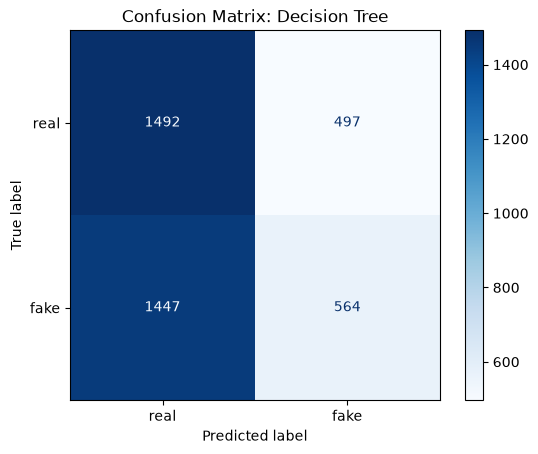

In [12]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(cmap="Blues")
plt.title("Confusion Matrix: Decision Tree")
plt.show()

## 8. Top-K Terms and Multicollinearity Check

The full TF-IDF matrix has 867 terms, which is too many to inspect one by one. PFI would have to shuffle every column, PDP/ICE would need hundreds of plots, and an 867 x 867 correlation matrix cannot be read. So we construct the top-K terms (K = 30), the terms most associated with the fake/real label according to a chi-squared score. The scores use training data only, so the test labels never influence which terms are chosen.

Chi-squared is a statistical score that measures how strongly a term is associated with the label. For each term, it compares how much of that term's TF-IDF weight falls in fake articles versus real articles, and checks whether the split differs from what we would expect if the term had nothing to do with the label. A higher score means a stronger association. It does not tell us which direction the term points (fake or real).

We chose chi-squared because it does not depend on any model, so every model can share the same top-K list and be compared fairly. It is also fast, gives the same answer every run, and works with TF-IDF because the weights are never negative. Since TF-IDF weights are continuous rather than counts, the scores are used only to rank terms, not as formal significance tests.

In [13]:
K = 30
top_idx, top_terms, top_scores = select_top_k_terms(X_train, y_train, feature_names, k=K, method="chi2")
pd.DataFrame({"term": top_terms, "chi2_score": top_scores}).head(7)

,term,chi2_score
0,economy,0.576492
1,particular,0.551777
2,significant,0.531097
3,model,0.517952
4,girl,0.503255
5,bring,0.501048
6,reflect,0.499708


The table shows the seven terms with the highest chi-squared scores, meaning the terms most strongly associated with the fake/real label in the training data. The terms (economy, particular, significant, model, girl, bring, reflect) are ordinary words rather than sensational or emotionally charged language, and the scores are low and close together (about 0.50 to 0.58), so no single term stands out. The table also does not say whether a term points toward fake or real.

All 30 terms are used in the analysis below, but only 7 are displayed at a time. Human working memory can hold about 7 ± 2 items at once, so limiting each table and plot to about 7 items lets the reader take it in at a glance without being overloaded.

A decision tree uses only a few terms, and they are not necessarily the ones with the highest chi-squared scores. The explanations below therefore cover the top-K terms together with the terms the tree actually splits on, so that every term the model uses is included in the correlation check and in the importance and feature-effect plots.

In [14]:
explain_idx = np.union1d(top_idx, used_idx)
explain_terms = feature_names[explain_idx]

print(f"Top-K terms: {len(top_idx)} | used by the tree: {len(used_idx)} | in both: {len(np.intersect1d(top_idx, used_idx))} | pool to explain: {len(explain_idx)}")

Top-K terms: 30 | used by the tree: 6 | in both: 3 | pool to explain: 33


In [15]:
X_test_dense = X_test.toarray().astype(np.float32)

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(X_test_dense.shape[0], size=500, replace=False)
X_sample = X_test_dense[sample_idx]          # 500-row sample for PDP/ICE and SHAP

The correlation heatmap checks whether any of the terms we explain move together across the training articles. Each cell shows the correlation between the TF-IDF weights of two terms, where 1 means they rise and fall together, -1 means one rises when the other falls, and 0 means no relationship. We also search for any pair above 0.5. This matters because the result decides which feature-effect technique we use later: PDP changes one term while holding the others fixed, which is only safe if the terms are not dependent on each other, and related terms can also split importance between them, which would distort PFI.

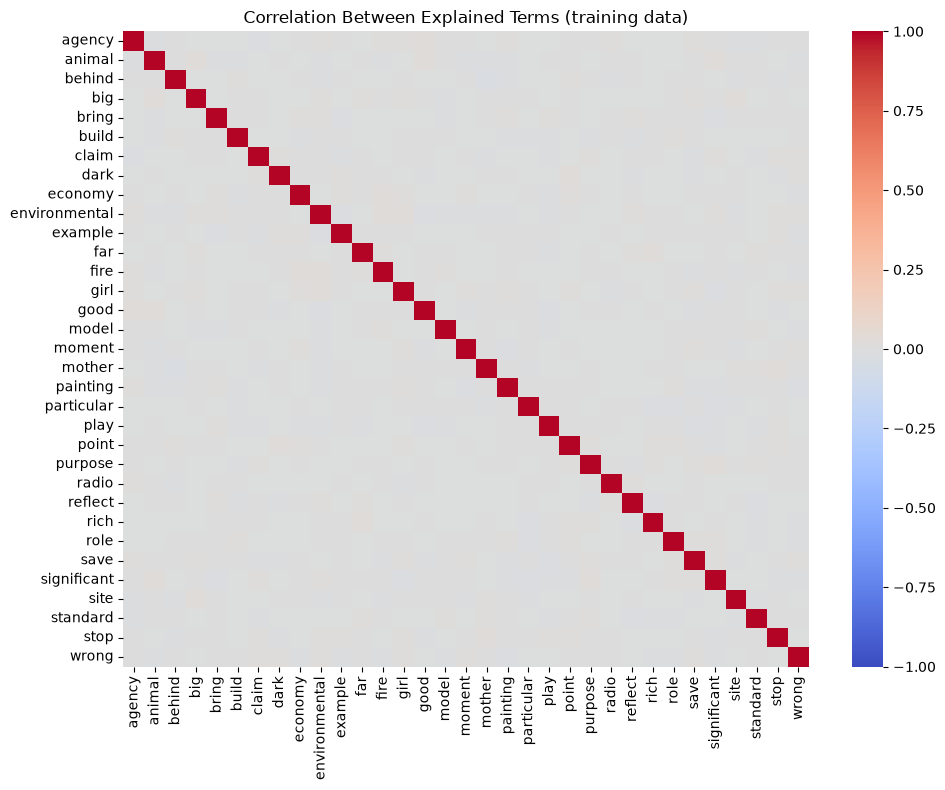

Pairs with |correlation| > 0.5:
Series([], dtype: float64)


In [16]:
X_train_explain = pd.DataFrame(X_train[:, explain_idx].toarray(), columns=explain_terms)
corr = X_train_explain.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Explained Terms (training data)")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Pairs with |correlation| > 0.5:")
print(pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False))

## 9. Global Importance (PFI and TreeSHAP)

What does the model rely on overall?

### 9.1 Permutation Feature Importance (PFI)

Each explained term is shuffled in the test set and the drop in Fake-class recall is measured (5 repeats). A large drop means the model relies on that term.

In [17]:
def permutation_recall_drop(model, X_dense, y_true, col_indices, n_repeats=5, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    base = recall_score(y_true, model.predict(X_dense), pos_label=1)
    rows = []
    for col in col_indices:
        original = X_dense[:, col].copy()
        drops = []
        for _ in range(n_repeats):
            X_dense[:, col] = rng.permutation(original)
            drops.append(base - recall_score(y_true, model.predict(X_dense), pos_label=1))
        X_dense[:, col] = original
        rows.append((feature_names[col], np.mean(drops), np.std(drops)))
    result = pd.DataFrame(rows, columns=["term", "mean_recall_drop", "std"])
    return base, result.sort_values("mean_recall_drop", ascending=False)

base_recall, pfi_df = permutation_recall_drop(dt, X_test_dense, y_test, explain_idx)
print(f"Recall before shuffling: {base_recall:.4f}")
pfi_df.head(7)

Recall before shuffling: 0.2805


,term,mean_recall_drop,std
14,good,0.003879,0.002096
32,wrong,0.000398,0.001818
9,environmental,0.000298,0.002366
0,agency,0.000000,0.000000
1,animal,0.000000,0.000000
5,build,0.000000,0.000000
6,claim,0.000000,0.000000


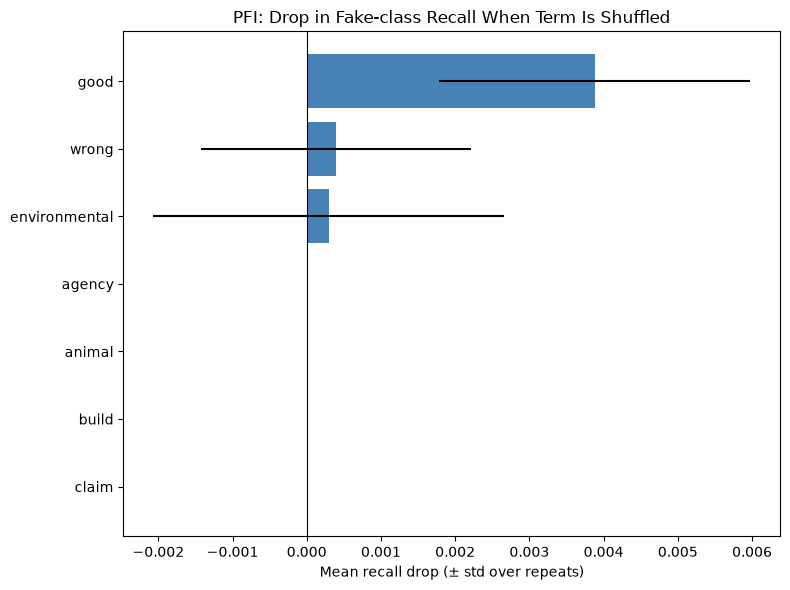

In [18]:
top_pfi = pfi_df.head(7).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_pfi["term"], top_pfi["mean_recall_drop"], xerr=top_pfi["std"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("PFI: Drop in Fake-class Recall When Term Is Shuffled")
plt.xlabel("Mean recall drop (± std over repeats)")
plt.tight_layout()
plt.show()

### 9.2 TreeSHAP (global view)

SHAP values attribute each prediction to individual terms (baseline + contributions = prediction). They are computed on a 200-article sample of the test set to keep runtime manageable, then averaged for a global view.

In [19]:
explainer_shap = shap.TreeExplainer(dt)
X_shap = X_sample[:200]

sv = explainer_shap.shap_values(X_shap, check_additivity=False)

# SHAP's output format differs by version; extract values for the FAKE class (index 1)
if isinstance(sv, list):
    sv_fake = sv[1]
elif sv.ndim == 3:
    sv_fake = sv[:, :, 1]
else:
    sv_fake = sv

ev = explainer_shap.expected_value
base_value = ev[1] if np.ndim(ev) > 0 else ev
print("SHAP values shape:", sv_fake.shape)

SHAP values shape: (200, 867)


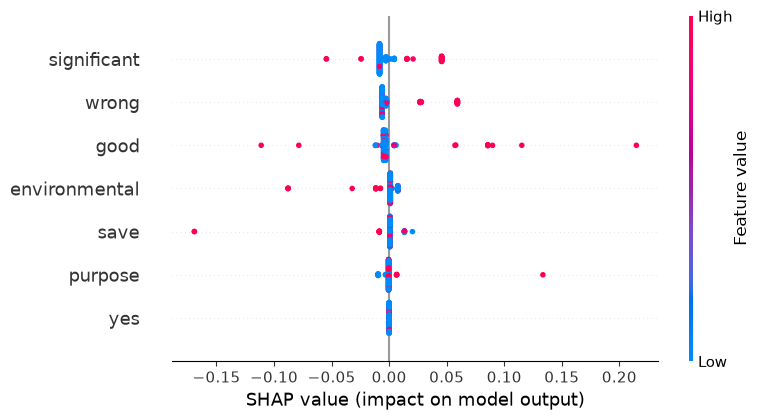

In [20]:
shap.summary_plot(sv_fake, X_shap, feature_names=list(feature_names), max_display=7)

In [21]:
shap_importance = pd.DataFrame({
    "term": feature_names,
    "mean_abs_shap": np.abs(sv_fake).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(7)

,term,mean_abs_shap
683,significant,0.012738
860,wrong,0.010781
316,good,0.010434
237,environmental,0.004185
649,save,0.003366
590,purpose,0.001729
4,account,0.000000


## 10. Feature Effects (PDP)

How does the average prediction change as a term's weight changes? The x-axis is the term's TF-IDF weight (0 = term absent).

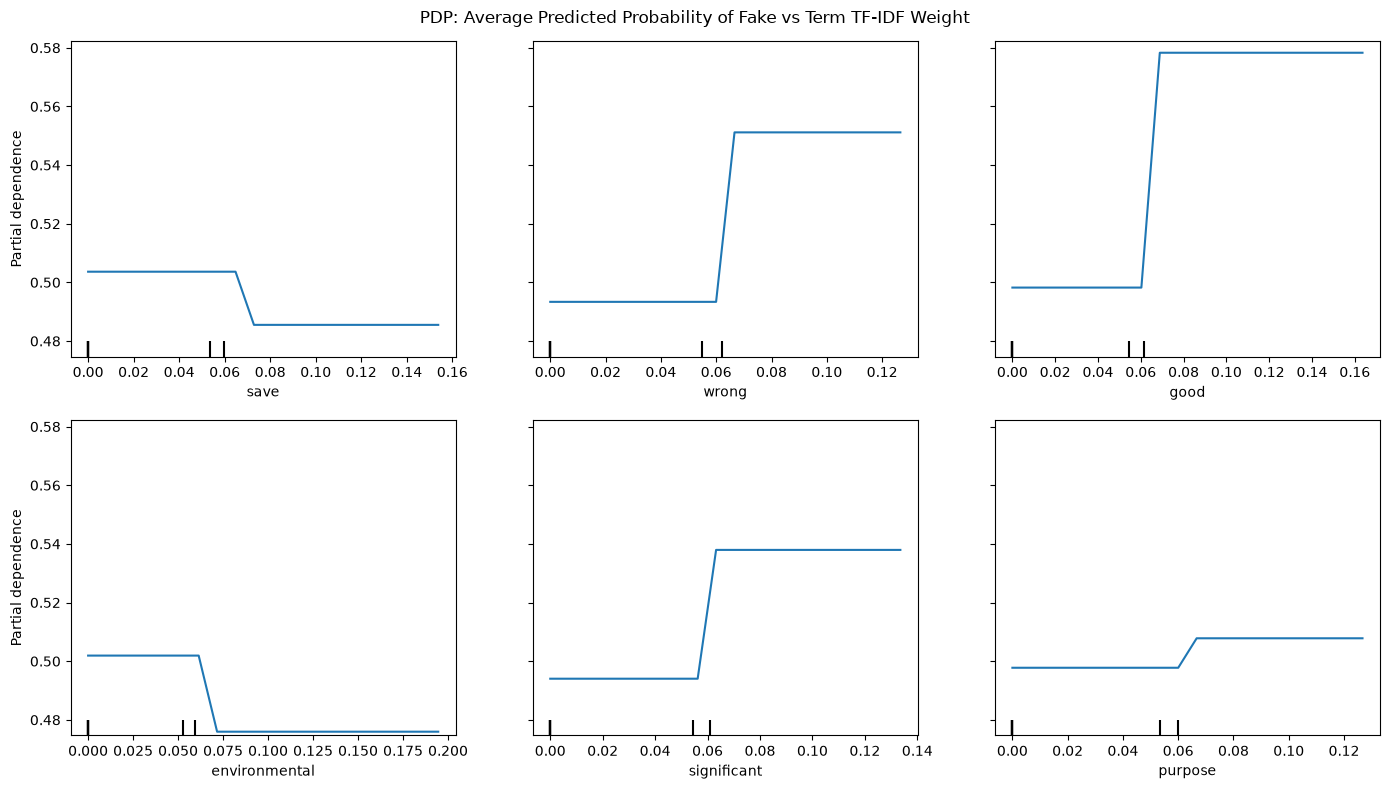

In [22]:
order = np.argsort(dt.feature_importances_)[::-1]
pdp_idx = [i for i in order[:6] if dt.feature_importances_[i] > 0]

pdp_display = PartialDependenceDisplay.from_estimator(
    dt, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="average",
    grid_resolution=20,
    percentiles=(0, 1),       # TF-IDF is mostly zeros, so the default 5-95% range would collapse to a single value
    n_cols=3,
    random_state=RANDOM_STATE,
)
pdp_display.figure_.set_size_inches(14, 8)
pdp_display.figure_.suptitle("PDP: Average Predicted Probability of Fake vs Term TF-IDF Weight")
plt.tight_layout()
plt.show()

## 11. Heterogeneity (ICE)

Is the effect the same for every article? Thin lines are individual articles; the dashed line is the PDP average. Parallel lines suggest little interaction; diverging or crossing lines suggest the term's effect depends on other terms in the article.

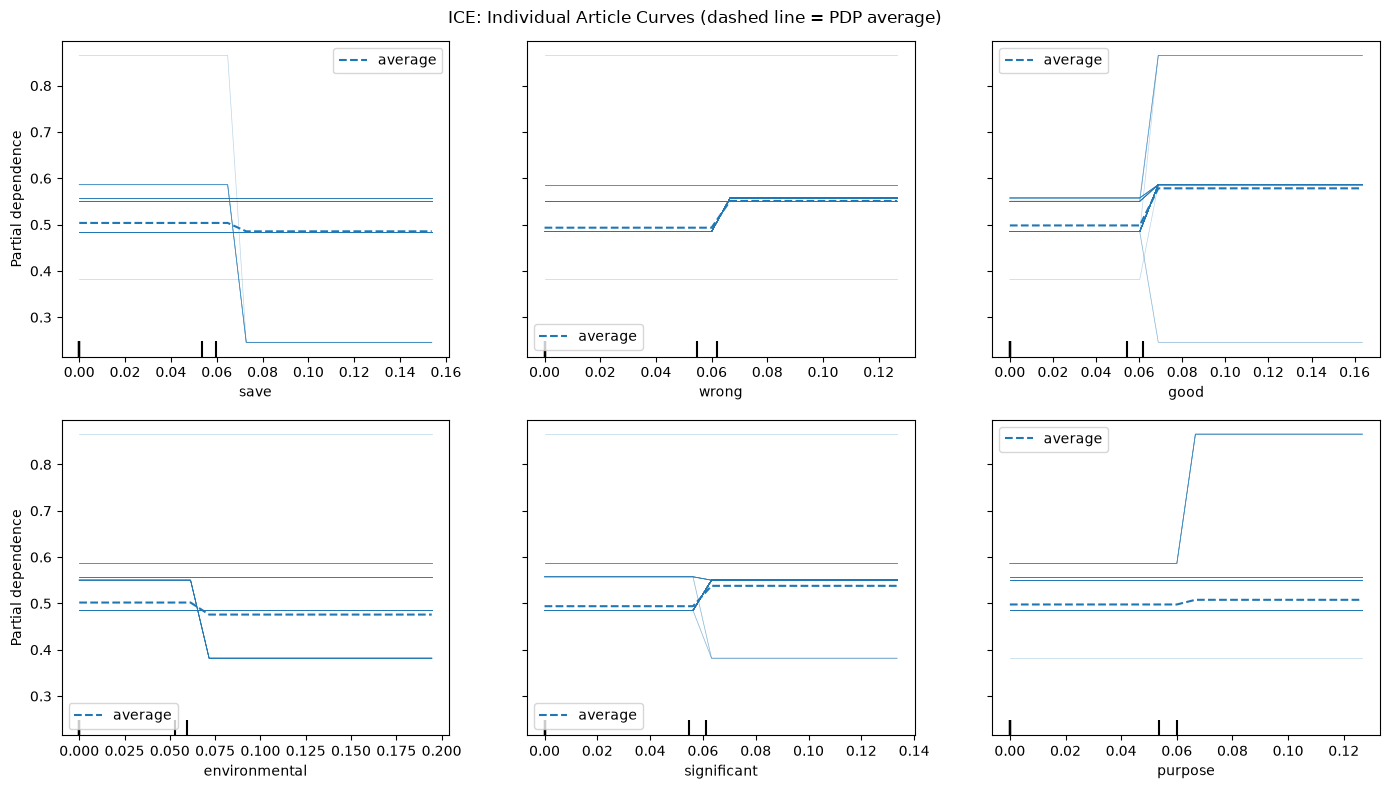

In [23]:
ice_display = PartialDependenceDisplay.from_estimator(
    dt, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="both",
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
ice_display.figure_.set_size_inches(14, 8)
ice_display.figure_.suptitle("ICE: Individual Article Curves (dashed line = PDP average)")
plt.tight_layout()
plt.show()

## 12. Individual Decisions (LIME and SHAP)

So far we have looked at why the model makes its decisions as a whole (global). Now we pick specific scenarios and ask why the model made this particular decision. We first use SP-LIME to let the data choose a small set of representative articles, and then look at three cases chosen by outcome: a fake article the model caught correctly, a fake article it missed, and a real article it wrongly flagged as fake. LIME and SHAP are used to show which terms pushed each prediction toward fake or toward real.

In [24]:
explainer_lime = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def predict_proba_text(texts):
    return dt.predict_proba(tfidf.transform(texts))

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true_arr = y_test.reset_index(drop=True).to_numpy()
y_pred_arr = np.asarray(y_pred)
proba_fake = dt.predict_proba(X_test)[:, 1]

tp = np.where((y_true_arr == 1) & (y_pred_arr == 1))[0]
fn = np.where((y_true_arr == 1) & (y_pred_arr == 0))[0]
fp = np.where((y_true_arr == 0) & (y_pred_arr == 1))[0]

cases = {
    "True Positive (fake, caught)":      tp[np.argmax(proba_fake[tp])],
    "False Negative (fake, missed)":     fn[np.argmin(proba_fake[fn])],
    "False Positive (real, flagged)":    fp[np.argmax(proba_fake[fp])],
}

### 12.1 SP-LIME: Choosing Representative Articles

LIME explains one article at a time, so the articles we look at matter. Instead of choosing them by hand, SP-LIME (submodular pick) generates LIME explanations for a pool of 200 test articles and then picks the 5 whose explanations together cover as many of the important words as possible, with as little repetition as possible. The pick is based on the words in the explanations, not on the article's category or whether it is fake, so after the pick we check which categories, labels and outcomes were selected.

In [25]:
N_CANDIDATES = 200
N_PICKS = 5

rng_sp = np.random.RandomState(RANDOM_STATE)
cand_idx = rng_sp.choice(len(test_text), size=N_CANDIDATES, replace=False)
cand_text = test_text.iloc[cand_idx].tolist()

sp = SubmodularPick(
    explainer_lime, cand_text, predict_proba_text,
    method="full",
    num_exps_desired=N_PICKS,
    num_features=7,
    num_samples=1000,
    top_labels=None          # explain the fake class (label 1) for every article
)
sp_idx = cand_idx[sp.V]      # positions of the picked articles in the test set

In [26]:
def outcome(i):
    t, p = int(y_true_arr[i]), int(y_pred_arr[i])
    return {(1, 1): "TP (fake, caught)", (1, 0): "FN (fake, missed)",
            (0, 1): "FP (real, flagged)", (0, 0): "TN (real, correct)"}[(t, p)]

sp_table = pd.DataFrame({
    "category": [df.loc[y_test.index[i], "category"] for i in sp_idx],
    "true_label": ["fake" if y_true_arr[i] == 1 else "real" for i in sp_idx],
    "P(fake)": [round(float(proba_fake[i]), 3) for i in sp_idx],
    "outcome": [outcome(i) for i in sp_idx],
})
display(sp_table)

,category,true_label,P(fake),outcome
0,Sports,fake,0.558,"TP (fake, caught)"
1,Science,fake,0.382,"FN (fake, missed)"
2,Business,real,0.586,"FP (real, flagged)"
3,Technology,real,0.485,"TN (real, correct)"
4,Entertainment,fake,0.586,"TP (fake, caught)"


SP-LIME pick 1 | P(fake) = 0.558


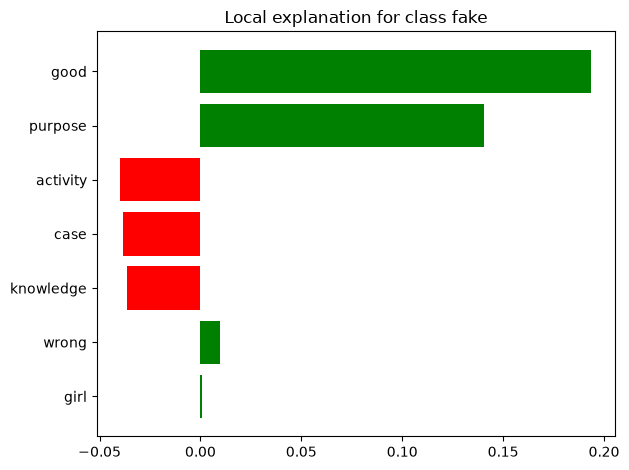

SP-LIME pick 2 | P(fake) = 0.382


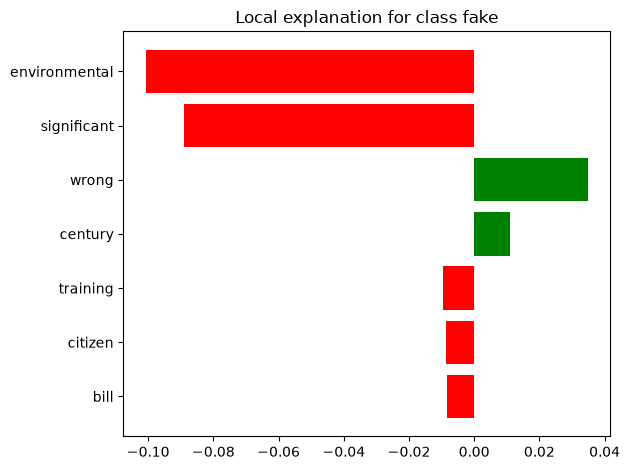

SP-LIME pick 3 | P(fake) = 0.586


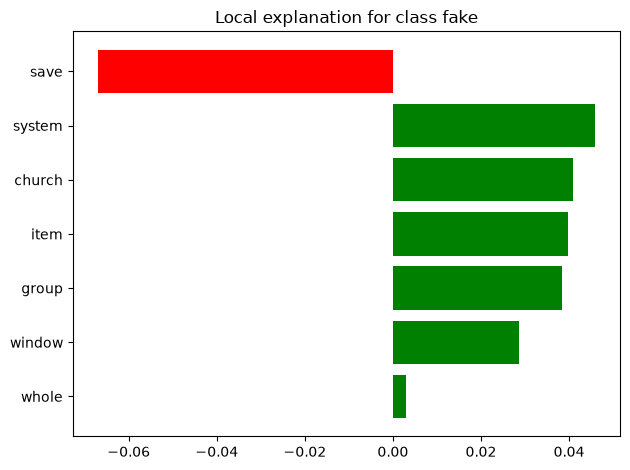

SP-LIME pick 4 | P(fake) = 0.485


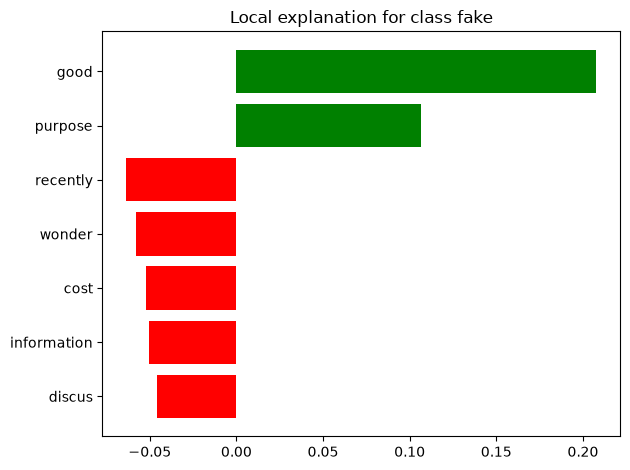

SP-LIME pick 5 | P(fake) = 0.586


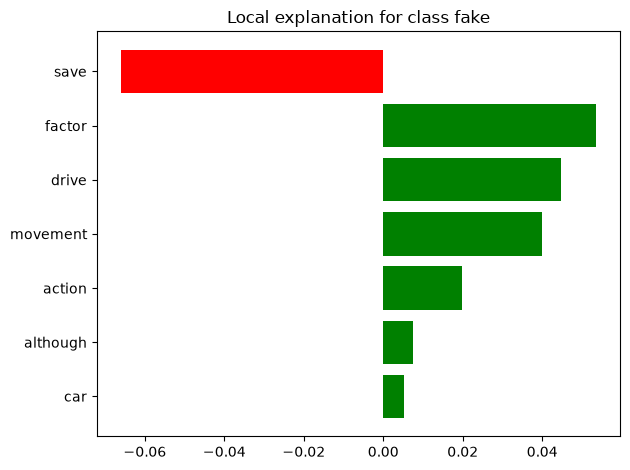

In [27]:
for rank, (exp, i) in enumerate(zip(sp.sp_explanations, sp_idx), start=1):
    print(f"SP-LIME pick {rank} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

### 12.2 LIME: Word-Removal Sanity Checks

LIME removes words from one article and watches how the predicted probability changes. Three cases are inspected: a correctly caught fake article (TP), a missed fake article (FN), and a real article wrongly flagged as fake (FP). Weights are for the fake class: positive = pushes toward fake.

True Positive (fake, caught) | P(fake) = 0.865


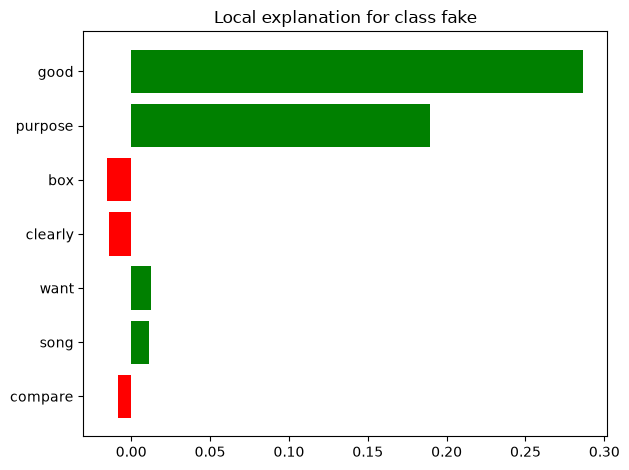

False Negative (fake, missed) | P(fake) = 0.246


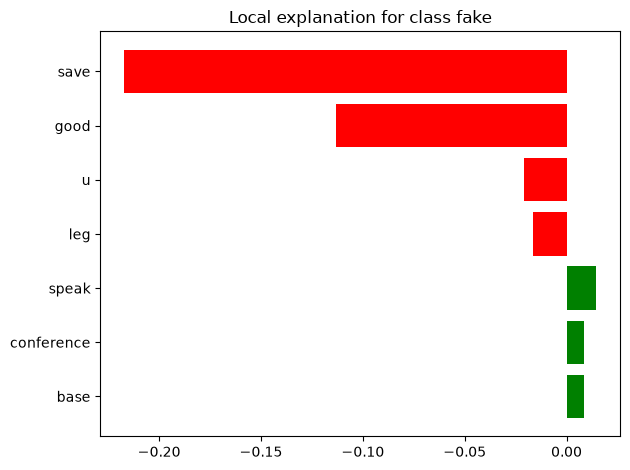

False Positive (real, flagged) | P(fake) = 0.865


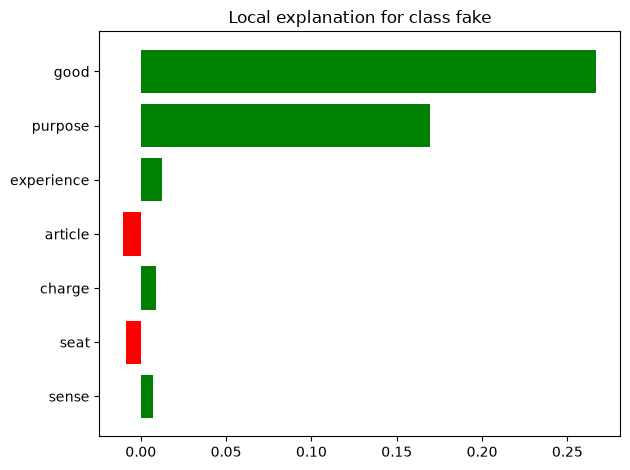

In [28]:
for name, i in cases.items():
    exp = explainer_lime.explain_instance(
        test_text.iloc[i], predict_proba_text,
        num_features=7, num_samples=1000, labels=(1,)
    )
    print(f"{name} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

### 12.3 SHAP Waterfall (one article)

LIME explains one prediction by approximating the model around that article, whereas SHAP splits the model's own prediction into a starting value plus one contribution per term that adds up exactly to the final probability, so the waterfall gives an exact term-by-term breakdown for one example article.

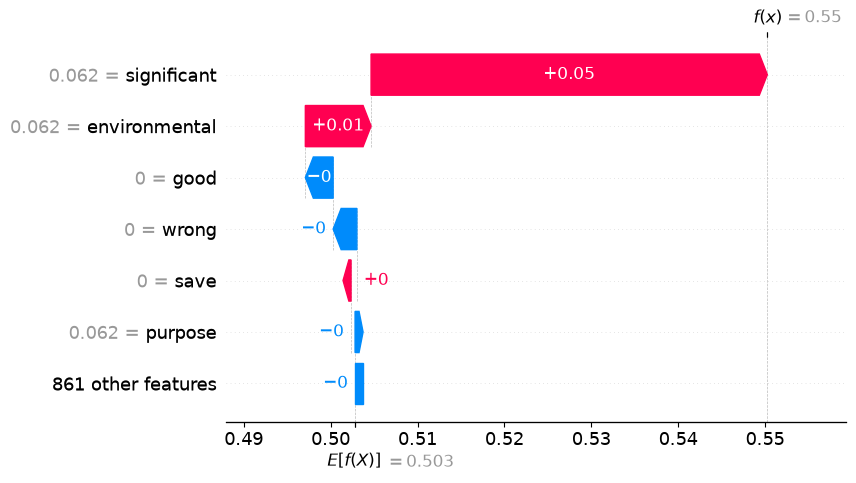

In [29]:
shap.plots.waterfall(
    shap.Explanation(
        values=sv_fake[0], base_values=base_value,
        data=X_shap[0], feature_names=list(feature_names)
    ),
    max_display=7
)

## 13. Summary